#### Food Price Analysis: Trends, Regional Variation & Price Volatility

- Name: Shrapti Bedre
- Course: Data Analytics
- Tools: Python, Pandas, NumPy, Matplotlib, Seaborn

##### Problem Statement

Food prices can vary significantly across countries, regions, markets, commodities, and time periods.

The objective of this project is to analyze food price data to identify:

- Food price trends over time
- Differences in prices across countries and regions
- Commodities with higher and lower prices
- Price variations across markets
- Changes in food prices over different years
- Major patterns and price volatility

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [5]:
df = pd.read_csv(
    r"C:\Users\Shrapti\Downloads\wfp_market_food_prices.csv\wfp_market_food_prices.csv",
    encoding="latin1"
)

In [6]:
df.head()

,adm0_id,adm0_name,adm1_id,adm1_name,mkt_id,mkt_name,cm_id,cm_name,cur_id,cur_name,pt_id,pt_name,um_id,um_name,mp_month,mp_year,mp_price,mp_commoditysource
0,1,Afghanistan,272,Badakhshan,266,Fayzabad,55,Bread,87,AFN,15,Retail,5,KG,1,2014,50.0,WFP
1,1,Afghanistan,272,Badakhshan,266,Fayzabad,55,Bread,87,AFN,15,Retail,5,KG,2,2014,50.0,WFP
2,1,Afghanistan,272,Badakhshan,266,Fayzabad,55,Bread,87,AFN,15,Retail,5,KG,3,2014,50.0,WFP
3,1,Afghanistan,272,Badakhshan,266,Fayzabad,55,Bread,87,AFN,15,Retail,5,KG,4,2014,50.0,WFP
4,1,Afghanistan,272,Badakhshan,266,Fayzabad,55,Bread,87,AFN,15,Retail,5,KG,5,2014,50.0,WFP


In [7]:
df.shape

(743914, 18)

In [25]:
df.rename(columns={
    'adm0_name': 'country',
    'adm1_name': 'region',
    'mkt_name': 'market',
    'cm_name': 'commodity',
    'cur_name': 'currency',
    'pt_name': 'price_type',
    'um_name': 'unit',
    'mp_month': 'month',
    'mp_year': 'year',
    'mp_price': 'price',
    'mp_commoditysource': 'commodity_source'
}, inplace=True)

In [22]:
df.columns

Index(['adm0_id', 'country', 'adm1_id', 'region', 'mkt_id', 'market', 'cm_id',
       'commodity', 'cur_id', 'currency', 'pt_id', 'price_type', 'um_id',
       'unit', 'month', 'year', 'price', 'commodity_source'],
      dtype='str')

In [26]:
df.columns = df.columns.str.lower()


In [27]:
df.columns.tolist()

['adm0_id',
 'country',
 'adm1_id',
 'region',
 'mkt_id',
 'market',
 'cm_id',
 'commodity',
 'cur_id',
 'currency',
 'pt_id',
 'price_type',
 'um_id',
 'unit',
 'month',
 'year',
 'price',
 'commodity_source']

In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 743914 entries, 0 to 743913
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   adm0_id           743914 non-null  int64  
 1   country           743914 non-null  str    
 2   adm1_id           743914 non-null  int64  
 3   region            729965 non-null  str    
 4   mkt_id            743914 non-null  int64  
 5   market            743914 non-null  str    
 6   cm_id             743914 non-null  int64  
 7   commodity         743914 non-null  str    
 8   cur_id            743914 non-null  int64  
 9   currency          743914 non-null  str    
 10  pt_id             743914 non-null  int64  
 11  price_type        743914 non-null  str    
 12  um_id             743914 non-null  int64  
 13  unit              743914 non-null  str    
 14  month             743914 non-null  int64  
 15  year              743914 non-null  int64  
 16  price             743914 non-nu

In [29]:
df.describe()

,adm0_id,adm1_id,mkt_id,cm_id,cur_id,pt_id,um_id,month,year,price
count,743914.000000,743914.000000,743914.000000,743914.000000,743914.000000,743914.000000,743914.000000,743914.000000,743914.000000,7.439140e+05
mean,929.754832,17779.426232,885.962341,161.130914,57.325319,14.930508,10.562171,6.379772,2012.516549,4.196333e+03
std,6595.353806,81345.242217,540.492854,117.826297,23.140366,0.277872,13.160485,3.434972,3.669519,5.549296e+04
min,1.000000,0.000000,80.000000,50.000000,22.000000,14.000000,5.000000,1.000000,1992.000000,0.000000e+00
25%,115.000000,1510.000000,377.000000,67.000000,30.000000,15.000000,5.000000,3.000000,2011.000000,3.000000e+01
50%,170.000000,2207.000000,912.000000,110.000000,63.000000,15.000000,5.000000,6.000000,2013.000000,1.750000e+02
75%,205.000000,21969.000000,1134.000000,233.000000,77.000000,15.000000,5.000000,9.000000,2015.000000,5.000000e+02
max,70001.000000,900022.000000,2094.000000,490.000000,95.000000,18.000000,100.000000,12.000000,2017.000000,5.833333e+06


In [30]:
df.head()

,adm0_id,country,adm1_id,region,mkt_id,market,cm_id,commodity,cur_id,currency,pt_id,price_type,um_id,unit,month,year,price,commodity_source
0,1,Afghanistan,272,Badakhshan,266,Fayzabad,55,Bread,87,AFN,15,Retail,5,KG,1,2014,50.0,WFP
1,1,Afghanistan,272,Badakhshan,266,Fayzabad,55,Bread,87,AFN,15,Retail,5,KG,2,2014,50.0,WFP
2,1,Afghanistan,272,Badakhshan,266,Fayzabad,55,Bread,87,AFN,15,Retail,5,KG,3,2014,50.0,WFP
3,1,Afghanistan,272,Badakhshan,266,Fayzabad,55,Bread,87,AFN,15,Retail,5,KG,4,2014,50.0,WFP
4,1,Afghanistan,272,Badakhshan,266,Fayzabad,55,Bread,87,AFN,15,Retail,5,KG,5,2014,50.0,WFP


In [31]:
df.tail()

,adm0_id,country,adm1_id,region,mkt_id,market,cm_id,commodity,cur_id,currency,pt_id,price_type,um_id,unit,month,year,price,commodity_source
743909,70001,South Sudan,2750,Eastern Equatoria,1786,Torit,156,Sesame,83,SSP,15,Retail,47,3.5 KG,5,2017,400.0,WFP
743910,70001,South Sudan,2750,Eastern Equatoria,1786,Torit,284,Fuel (diesel),83,SSP,15,Retail,15,L,2,2017,12.5,WFP
743911,70001,South Sudan,2750,Eastern Equatoria,1786,Torit,284,Fuel (diesel),83,SSP,15,Retail,15,L,3,2017,95.0,WFP
743912,70001,South Sudan,2750,Eastern Equatoria,1786,Torit,285,Fuel (petrol-gasoline),83,SSP,15,Retail,15,L,2,2017,95.0,WFP
743913,70001,South Sudan,2750,Eastern Equatoria,1786,Torit,285,Fuel (petrol-gasoline),83,SSP,15,Retail,15,L,3,2017,93.7,WFP


In [32]:
df.isnull().sum()

adm0_id                 0
country                 0
adm1_id                 0
region              13949
mkt_id                  0
market                  0
cm_id                   0
commodity               0
cur_id                  0
currency                0
pt_id                   0
price_type              0
um_id                   0
unit                    0
month                   0
year                    0
price                   0
commodity_source        0
dtype: int64

In [33]:
(df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

region              1.875082
adm0_id             0.000000
country             0.000000
adm1_id             0.000000
mkt_id              0.000000
market              0.000000
cm_id               0.000000
commodity           0.000000
cur_id              0.000000
currency            0.000000
pt_id               0.000000
price_type          0.000000
um_id               0.000000
unit                0.000000
month               0.000000
year                0.000000
price               0.000000
commodity_source    0.000000
dtype: float64

In [36]:
missing_region_pct = (df['region'].isnull().sum() / len(df)) * 100
print("Missing region:", df['region'].isnull().sum())
print("Percentage:", round(missing_region_pct, 2), "%")

Missing region: 13949
Percentage: 1.88 %


In [34]:
df.duplicated().sum()

np.int64(0)

In [35]:
df.dtypes

adm0_id               int64
country                 str
adm1_id               int64
region                  str
mkt_id                int64
market                  str
cm_id                 int64
commodity               str
cur_id                int64
currency                str
pt_id                 int64
price_type              str
um_id                 int64
unit                    str
month                 int64
year                  int64
price               float64
commodity_source        str
dtype: object

In [37]:
df['price'].describe()

count    7.439140e+05
mean     4.196333e+03
std      5.549296e+04
min      0.000000e+00
25%      3.000000e+01
50%      1.750000e+02
75%      5.000000e+02
max      5.833333e+06
Name: price, dtype: float64

In [38]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 30.0
Q3: 500.0
IQR: 470.0
Lower Limit: -675.0
Upper Limit: 1205.0


In [39]:
outliers = df[(df['price'] < lower_limit) | (df['price'] > upper_limit)]

print("Number of outliers:", len(outliers))

Number of outliers: 119896


In [40]:
zero_prices = df[df['price'] == 0]

print("Number of zero price records:", len(zero_prices))

Number of zero price records: 19


In [41]:
zero_prices[['country', 'market', 'commodity', 'currency', 'price']].head(10)

,country,market,commodity,currency,price
124505,Gambia,Kaur Wharf Town,Fonio,GMD,0.0
228443,Jordan,National Average,Oranges (big size),JOD,0.0
257167,Lao People's Democratic Republic,Luang Prabang,Fish (snake head),LAK,0.0
263534,Lao People's Democratic Republic,Bokeo,Fish (snake head),LAK,0.0
263535,Lao People's Democratic Republic,Bokeo,Fish (snake head),LAK,0.0
263536,Lao People's Democratic Republic,Bokeo,Fish (snake head),LAK,0.0
612151,Syrian Arab Republic,Deir Ezzor,Dates,SYP,0.0
612295,Syrian Arab Republic,Deir Ezzor,Cheese,SYP,0.0
612308,Syrian Arab Republic,Deir Ezzor,Parsley,SYP,0.0
641975,Tajikistan,Khorog,Wage (qualified labour),TJS,0.0


In [42]:
df = df[df['price'] > 0].copy()

print("Shape after removing zero prices:", df.shape)

Shape after removing zero prices: (743895, 18)


In [43]:
print("Number of countries:", df['country'].nunique())
print("Number of regions:", df['region'].nunique())
print("Number of markets:", df['market'].nunique())
print("Number of commodities:", df['commodity'].nunique())
print("Number of currencies:", df['currency'].nunique())
print("Number of price types:", df['price_type'].nunique())
print("Number of units:", df['unit'].nunique())

Number of countries: 74
Number of regions: 588
Number of markets: 1449
Number of commodities: 321
Number of currencies: 61
Number of price types: 4
Number of units: 62


In [44]:
print("Top 10 Countries:")
print(df['country'].value_counts().head(10))

print("\nTop 10 Commodities:")
print(df['commodity'].value_counts().head(10))

print("\nPrice Types:")
print(df['price_type'].value_counts())

Top 10 Countries:
country
Rwanda                              115037
India                                68308
Niger                                36195
Mali                                 32702
Democratic Republic of the Congo     29997
Zambia                               26374
Ukraine                              25766
Senegal                              22783
Mozambique                           22652
Gambia                               21574
Name: count, dtype: int64

Top 10 Commodities:
commodity
Maize              36582
Millet             33889
Sorghum            31037
Rice (imported)    26606
Rice               24210
Maize (white)      20875
Rice (local)       20620
Sugar              19059
Wheat              17944
Wheat flour        17077
Name: count, dtype: int64

Price Types:
price_type
Retail       688859
Wholesale     54144
Farm Gate       664
Producer        228
Name: count, dtype: int64


#### 1. Univariate Analysis

- Univariate analysis is used to understand the distribution and characteristics of individual variables in the dataset.

#### 1.1 Price Distribution

- The distribution of food prices is analyzed using a histogram.
- This helps us understand how frequently different price ranges occur in the dataset.

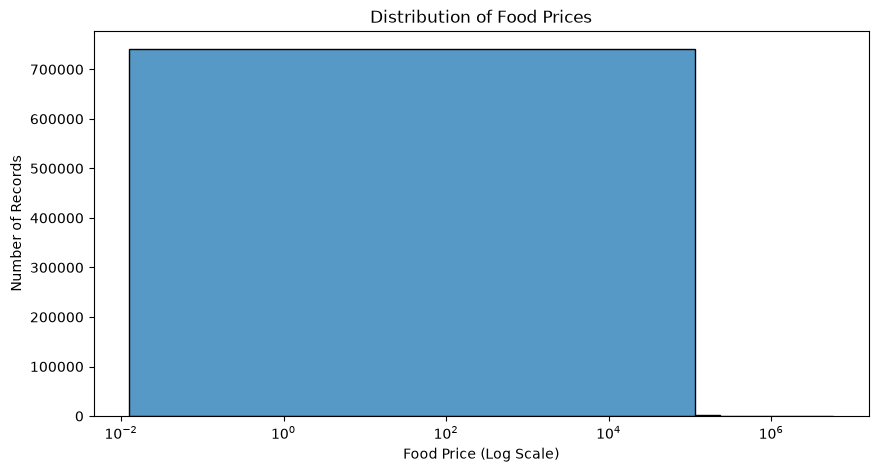

In [47]:
plt.figure(figsize=(10, 5))

sns.histplot(df['price'], bins=50)

plt.xscale('log')

plt.xlabel('Food Price (Log Scale)')
plt.ylabel('Number of Records')
plt.title('Distribution of Food Prices')

plt.show()

#### Interpretation

- The food price distribution is highly right-skewed. Most observations have relatively lower prices, while a smaller number of observations have very high prices.

- The large variation in prices is expected because the dataset contains food price records from different countries, markets, commodities, currencies, and units.

- A logarithmic scale is used to make the distribution easier to visualize.

#### 1.2 Top 10 Most Frequently Recorded Commodities

- This analysis identifies the commodities with the highest number of records in the dataset.
- It helps us understand which food commodities are most represented in the dataset.

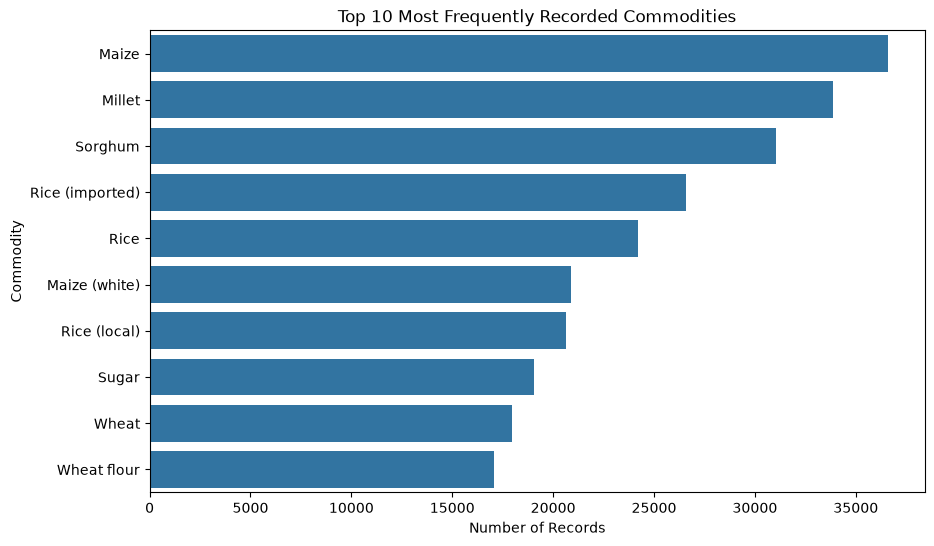

In [48]:
top_commodities = df['commodity'].value_counts().head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_commodities.values,
    y=top_commodities.index
)

plt.xlabel('Number of Records')
plt.ylabel('Commodity')
plt.title('Top 10 Most Frequently Recorded Commodities')

plt.show()

#### 1.3 Top 10 Countries by Number of Records

- This analysis identifies the countries with the highest number of food price records.
- It helps us understand which countries are most represented in the dataset.

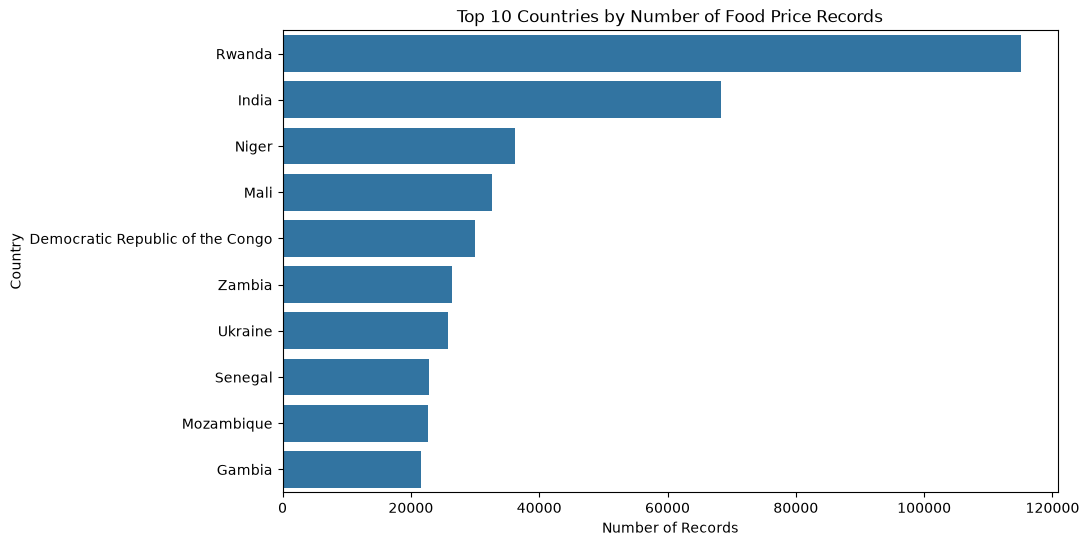

In [49]:
top_countries = df['country'].value_counts().head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.xlabel('Number of Records')
plt.ylabel('Country')
plt.title('Top 10 Countries by Number of Food Price Records')

plt.show()

In [ ]:
### Interpretation

The bar chart shows the 10 countries with the highest number of food price records.
The number of records varies across countries, indicating that the dataset is not equally represented across all countries.
Countries with more records have greater representation in the dataset and may influence overall analysis more strongly.

#### 1.4 Price Type Distribution

- This analysis shows the distribution of food price records across different price types.
- It helps us understand which types of prices are most commonly recorded in the dataset.

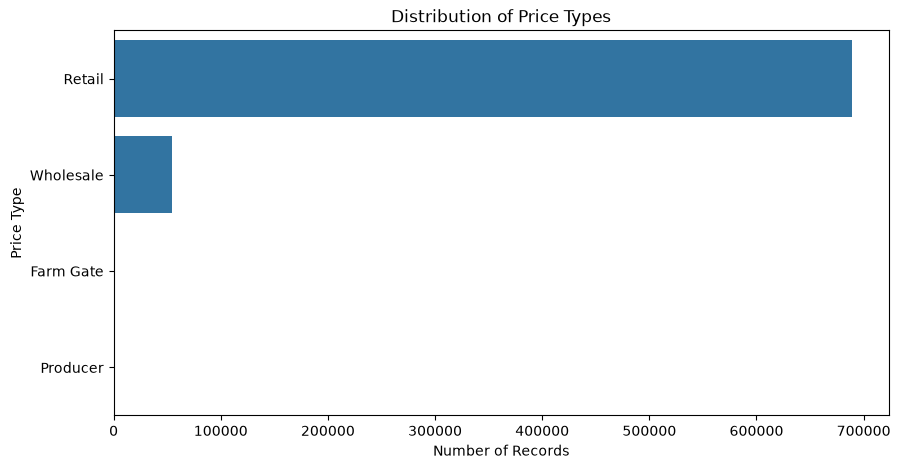

In [50]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    y='price_type',
    order=df['price_type'].value_counts().index
)

plt.xlabel('Number of Records')
plt.ylabel('Price Type')
plt.title('Distribution of Price Types')

plt.show()

### Interpretation

The chart shows the number of records available for each price type.
The most frequently recorded price type has the highest number of observations, while other price types have comparatively fewer records.
This indicates that the dataset has an unequal representation of different price types.

### 1.5 Year-wise Distribution of Food Price Records

This analysis shows the number of food price records available for each year.
It helps us understand the time coverage and representation of the dataset.

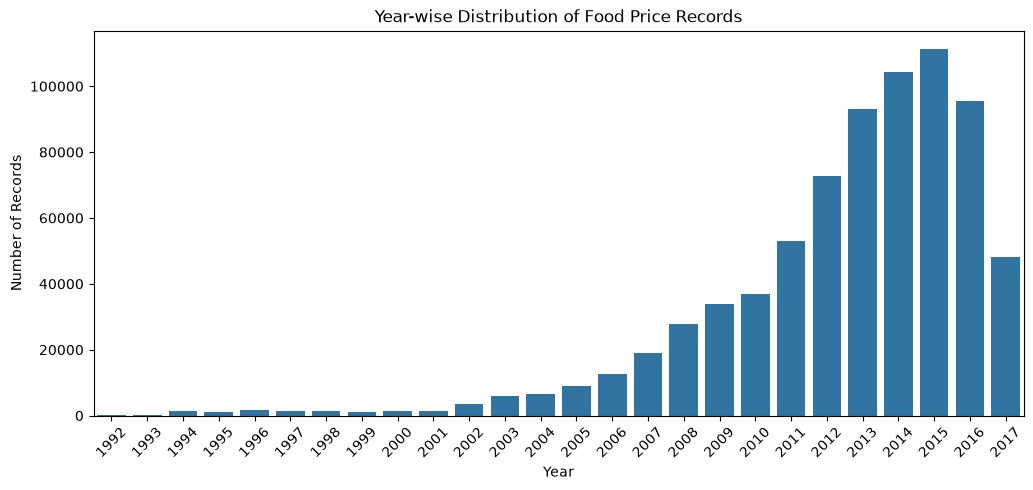

In [51]:
year_counts = df['year'].value_counts().sort_index()

plt.figure(figsize=(12, 5))

sns.barplot(
    x=year_counts.index,
    y=year_counts.values
)

plt.xlabel('Year')
plt.ylabel('Number of Records')
plt.title('Year-wise Distribution of Food Price Records')

plt.xticks(rotation=45)

plt.show()

### Interpretation

The chart shows how food price records are distributed across different years.
The number of observations varies across years, indicating that some years have greater representation in the dataset than others.
This provides an overview of the time coverage of the available food price data.

### Bivariate Analysis

## 2. Bivariate Analysis

Bivariate analysis is used to understand the relationship between two variables.
In this section, food prices are compared with time, commodities, and countries.

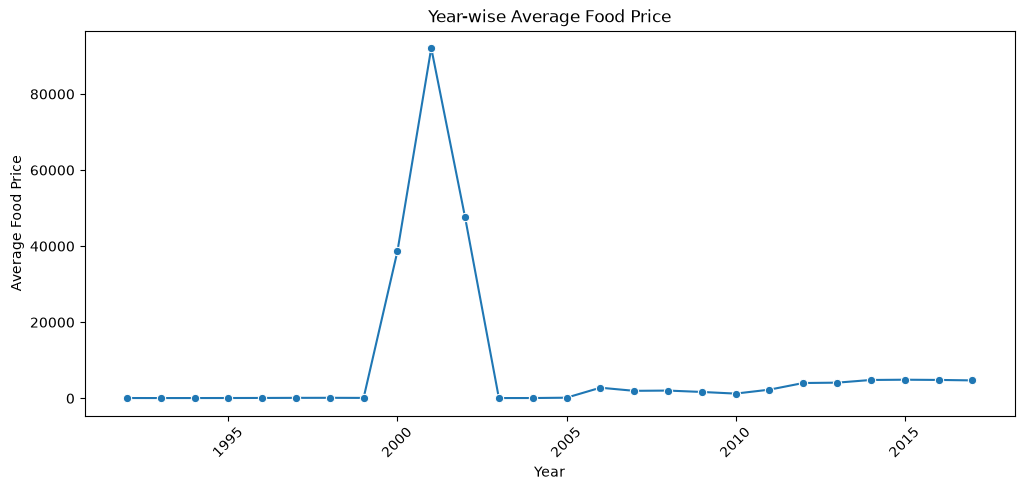

In [52]:
year_price = df.groupby('year')['price'].mean().reset_index()

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=year_price,
    x='year',
    y='price',
    marker='o'
)

plt.xlabel('Year')
plt.ylabel('Average Food Price')
plt.title('Year-wise Average Food Price')

plt.xticks(rotation=45)

plt.show()

### Interpretation

The line chart shows how the average recorded food price changes across different years.
The trend indicates the overall movement of food prices over time.
Changes in the average price may reflect differences in market conditions, commodities, countries, and other economic factors represented in the dataset.

### 2.2 Commodity-wise Average Food Price

This analysis compares the average recorded food price across the most frequently recorded commodities.

It helps us understand how the recorded prices differ across major commodities.

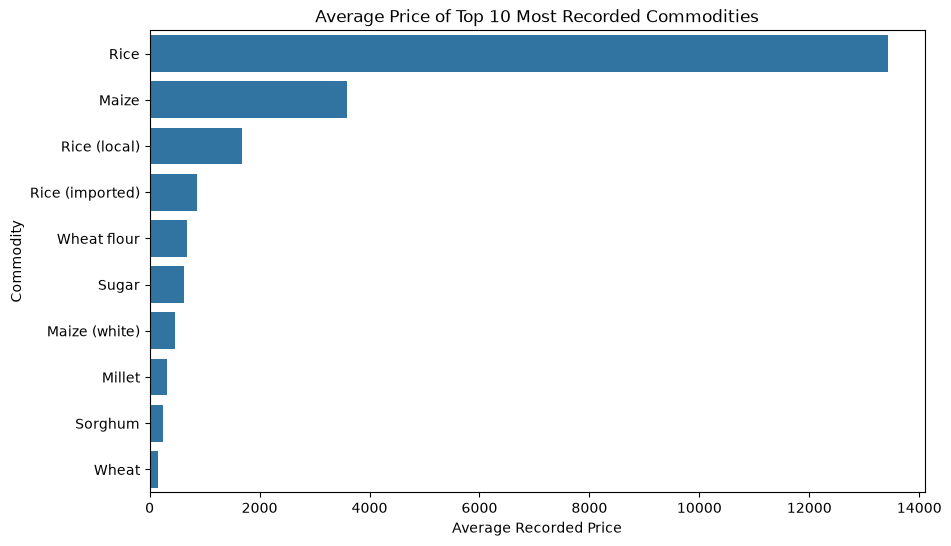

In [53]:
top_10_commodities = df['commodity'].value_counts().head(10).index

commodity_price = (
    df[df['commodity'].isin(top_10_commodities)]
    .groupby('commodity')['price']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=commodity_price.values,
    y=commodity_price.index
)

plt.xlabel('Average Recorded Price')
plt.ylabel('Commodity')
plt.title('Average Price of Top 10 Most Recorded Commodities')

plt.show()

### Interpretation

The bar chart compares the average recorded price of the 10 most frequently recorded commodities.

The average price varies across commodities, showing differences in recorded food prices.

However, the prices should not be interpreted as direct global commodity price comparisons because the dataset contains different currencies and units.

### 2.3 Country-wise Average Food Price

This analysis compares the average recorded food price across the 10 countries with the highest number of records.

It helps us observe how recorded food prices vary across different countries.

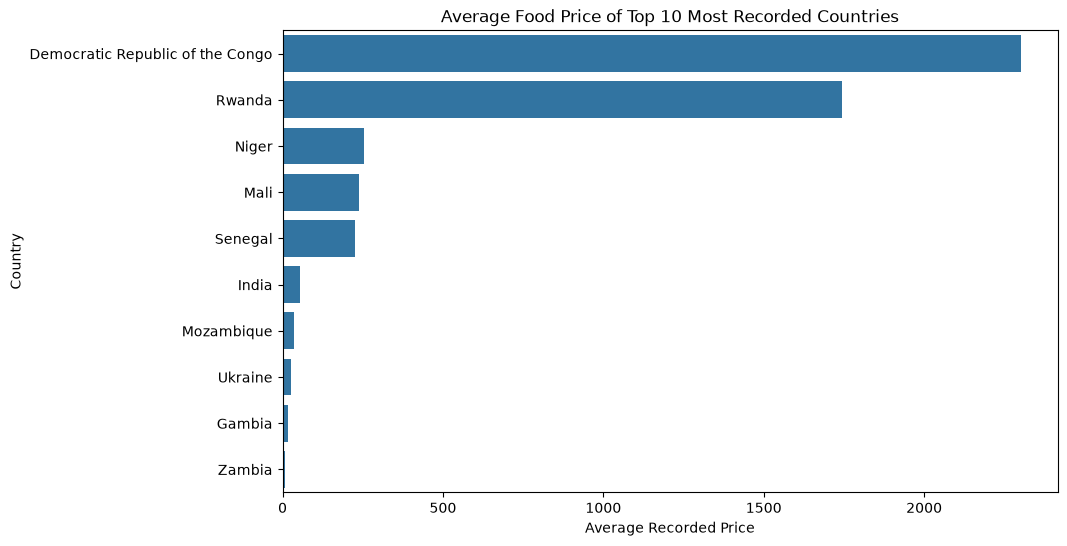

In [54]:
top_10_countries = df['country'].value_counts().head(10).index

country_price = (
    df[df['country'].isin(top_10_countries)]
    .groupby('country')['price']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=country_price.values,
    y=country_price.index
)

plt.xlabel('Average Recorded Price')
plt.ylabel('Country')
plt.title('Average Food Price of Top 10 Most Recorded Countries')

plt.show()

### Interpretation

The bar chart compares the average recorded food price across the 10 most frequently recorded countries.

The average recorded price differs between countries, indicating variation in the food price records.

However, these values should not be treated as direct comparisons of actual food prices between countries because the dataset contains different currencies, units, commodities, and market conditions.

### 2.4 Price Type vs Average Food Price

This analysis compares the average recorded food price for different price types.

It helps us understand how recorded prices differ across the available price categories.

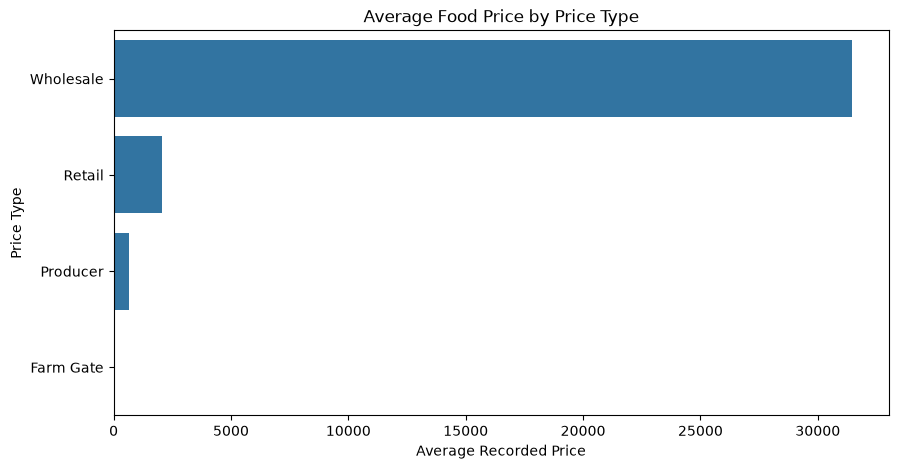

In [55]:
price_type_avg = (
    df.groupby('price_type')['price']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=price_type_avg.values,
    y=price_type_avg.index
)

plt.xlabel('Average Recorded Price')
plt.ylabel('Price Type')
plt.title('Average Food Price by Price Type')

plt.show()

### Interpretation

The bar chart shows the average recorded food price for each price type.

The average price differs across price types, indicating variation in the recorded food price values.

The results should be interpreted carefully because the dataset contains different currencies, units, commodities, and markets.

## 3. Multivariate Analysis

Multivariate analysis is used to understand relationships between multiple variables at the same time.

In this section, food prices are analyzed across different years, countries, and commodities.

### 3.1 Average Food Price by Year and Country

This analysis compares the average recorded food price across different years for the five countries with the highest number of records.

It helps us observe how recorded prices vary across both time and countries.

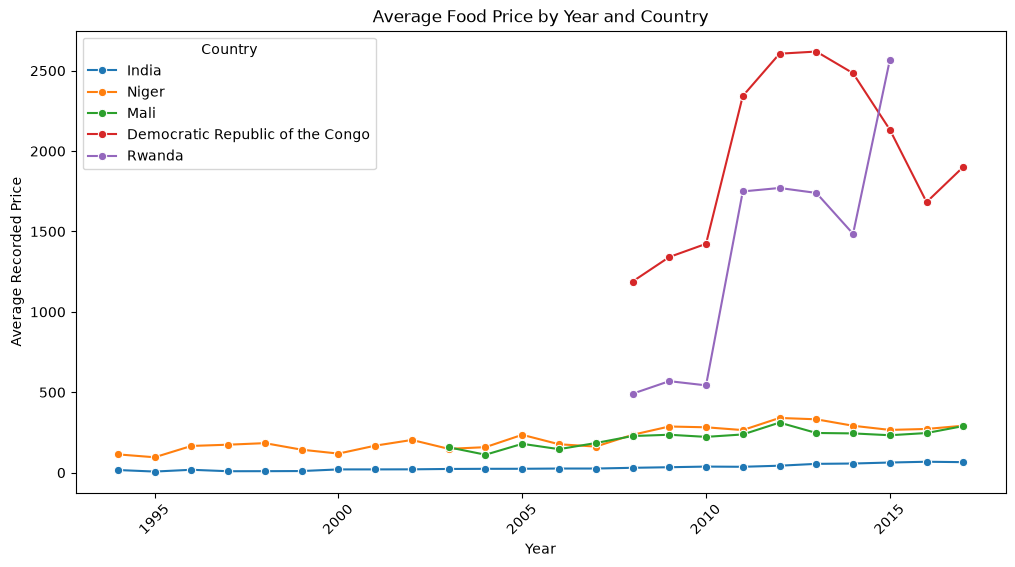

In [56]:
top_5_countries = df['country'].value_counts().head(5).index

multi_data = (
    df[df['country'].isin(top_5_countries)]
    .groupby(['year', 'country'])['price']
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=multi_data,
    x='year',
    y='price',
    hue='country',
    marker='o'
)

plt.xlabel('Year')
plt.ylabel('Average Recorded Price')
plt.title('Average Food Price by Year and Country')

plt.xticks(rotation=45)
plt.legend(title='Country')

plt.show()

### Interpretation

The line chart shows how the average recorded food price changes across years for the five most represented countries.

The trends are different across countries, showing that food price records vary over time and between countries.

The comparison should be interpreted carefully because the dataset contains different currencies, units, commodities, and market conditions.

### 3.2 Country, Commodity and Average Price

This analysis examines the average recorded food price across different countries and commodities.

It helps us understand how food price values vary when both country and commodity are considered together.

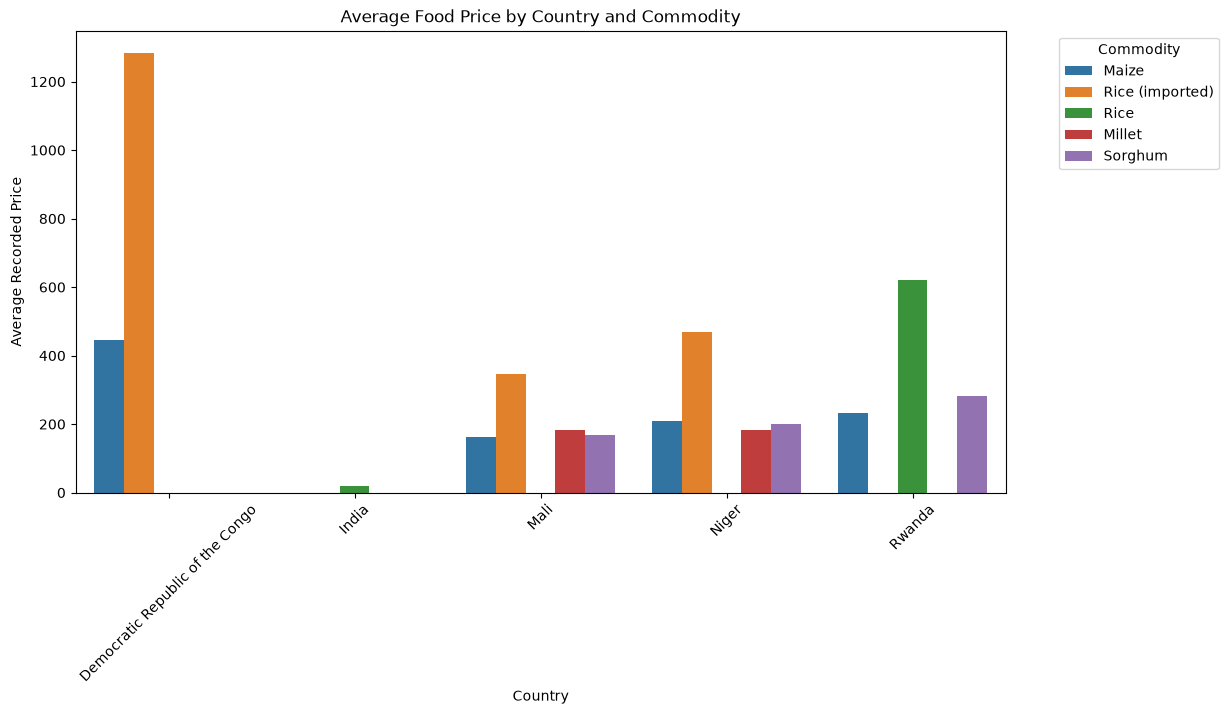

In [57]:
top_5_countries = df['country'].value_counts().head(5).index
top_5_commodities = df['commodity'].value_counts().head(5).index

multi_data = (
    df[
        df['country'].isin(top_5_countries) &
        df['commodity'].isin(top_5_commodities)
    ]
    .groupby(['country', 'commodity'])['price']
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=multi_data,
    x='country',
    y='price',
    hue='commodity'
)

plt.xlabel('Country')
plt.ylabel('Average Recorded Price')
plt.title('Average Food Price by Country and Commodity')

plt.xticks(rotation=45)
plt.legend(title='Commodity', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.show()

### Interpretation

The chart compares average recorded food prices across the selected countries and commodities.

The results show that price values vary depending on both the country and the commodity.

This demonstrates that food prices are influenced by multiple factors rather than a single variable.

Since the dataset contains different currencies and units, the recorded prices should be used mainly to identify patterns within the dataset rather than as direct international price comparisons.

## 4. Pivot Tables & Visual/Non-Visual Insights

Pivot tables are used to summarize the dataset and identify important patterns without looking at individual records.

### 4.1 Year-wise Average Food Price

This pivot table summarizes the average recorded food price for each year.
It helps us understand the overall price pattern across the available time period.

In [58]:
year_pivot = pd.pivot_table(
    df,
    values='price',
    index='year',
    aggfunc='mean'
)

year_pivot

,price
year,
1992,76.542955
1993,67.578258
1994,70.863290
1995,79.276649
1996,93.957951
1997,120.583331
1998,132.463900
1999,106.811847
2000,38654.672569


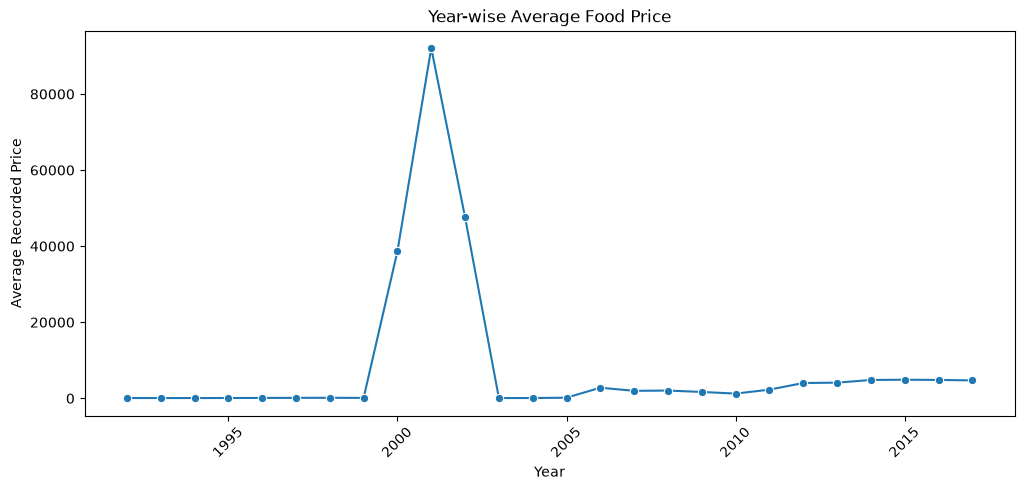

In [59]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=year_pivot,
    x=year_pivot.index,
    y='price',
    marker='o'
)

plt.xlabel('Year')
plt.ylabel('Average Recorded Price')
plt.title('Year-wise Average Food Price')

plt.xticks(rotation=45)

plt.show()

### Interpretation

The pivot table summarizes the average recorded food price for each year.

The results show that the average recorded price changes across different years.

This provides a simple numerical summary of the time-based price pattern.

Because the dataset contains different currencies and units, the values should be interpreted as recorded price patterns rather than direct global food price comparisons.

### 4.2 Country-wise Price Type Analysis

This pivot table shows the average recorded food price for different price types across countries.

It helps us compare price categories across the countries represented in the dataset.

In [60]:
country_price_type_pivot = pd.pivot_table(
    df,
    values='price',
    index='country',
    columns='price_type',
    aggfunc='mean'
)

country_price_type_pivot.head(10)

price_type,Farm Gate,Producer,Retail,Wholesale
country,,,,
Afghanistan,NaN,NaN,76208.495992,NaN
Algeria,NaN,NaN,164.130998,NaN
Armenia,NaN,NaN,821.170584,NaN
Azerbaijan,NaN,NaN,0.527840,NaN
Bangladesh,NaN,NaN,53.488742,NaN
Benin,NaN,NaN,331.647003,184.630615
Bhutan,NaN,NaN,26.141731,NaN
Bolivia,NaN,NaN,13.697535,NaN
Burkina Faso,NaN,NaN,161.022998,200.517799


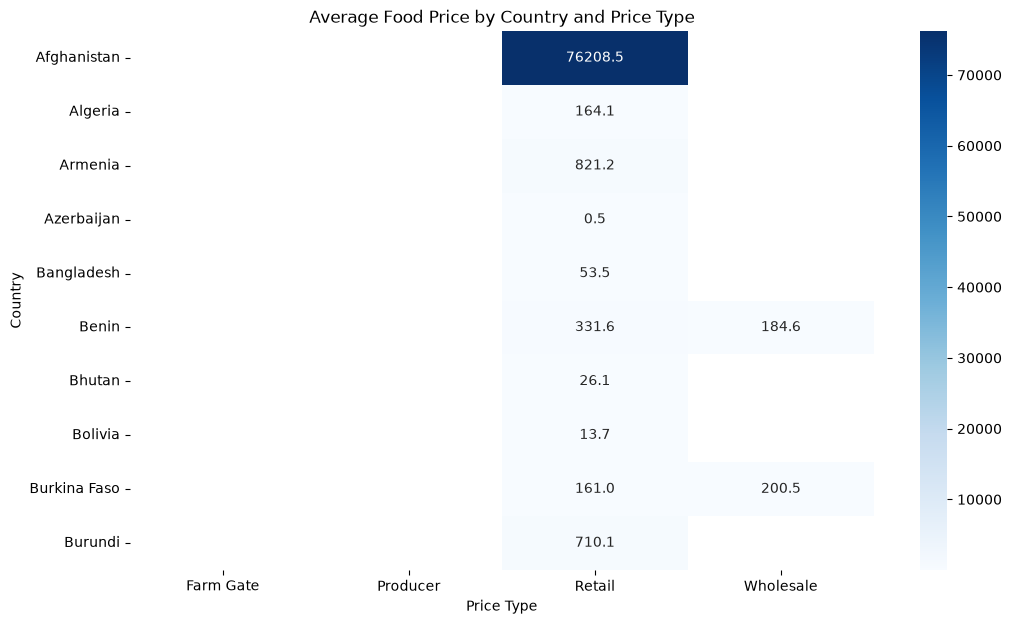

In [61]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    country_price_type_pivot.head(10),
    annot=True,
    fmt='.1f',
    cmap='Blues'
)

plt.xlabel('Price Type')
plt.ylabel('Country')
plt.title('Average Food Price by Country and Price Type')

plt.show()

### Interpretation

The pivot table summarizes the average recorded price across countries and price types.

The heatmap makes it easier to identify differences in recorded prices between countries and price categories.

Higher values indicate higher recorded prices within the displayed combinations.

The values should be interpreted carefully because different currencies, units, commodities, and market conditions are included in the dataset.

### 4.3 Country-wise Record Count

This summary shows the number of food price records available for each country.

It helps us understand how the dataset is distributed across countries and identify the countries with the highest representation.

In [62]:
country_record_pivot = pd.pivot_table(
    df,
    index='country',
    values='price',
    aggfunc='count'
).sort_values('price', ascending=False)

country_record_pivot.head(10)

,price
country,
Rwanda,115037
India,68308
Niger,36195
Mali,32702
Democratic Republic of the Congo,29997
Zambia,26374
Ukraine,25766
Senegal,22783
Mozambique,22652


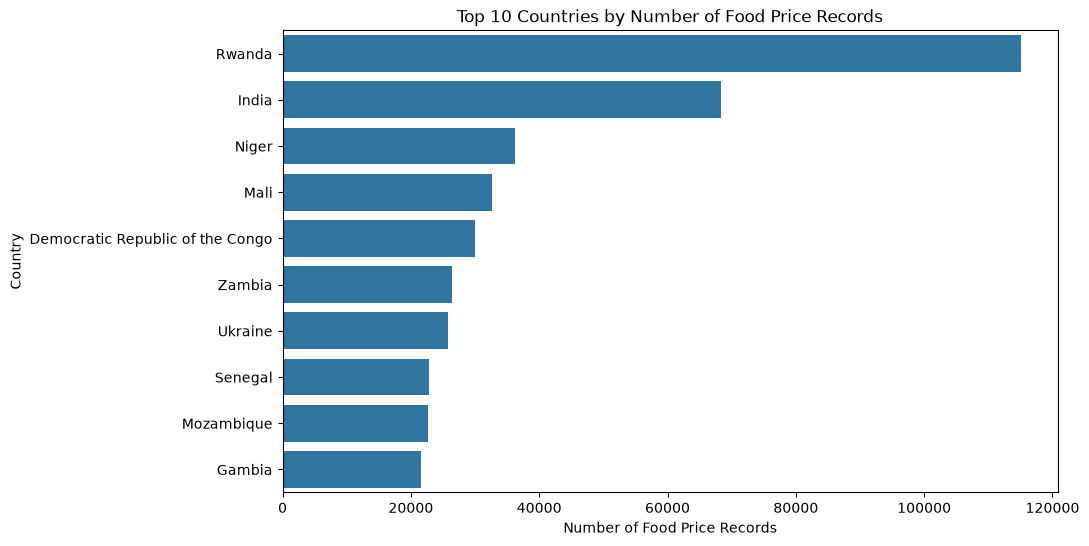

In [63]:
top_10_country_records = country_record_pivot.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_country_records['price'],
    y=top_10_country_records.index
)

plt.xlabel('Number of Food Price Records')
plt.ylabel('Country')
plt.title('Top 10 Countries by Number of Food Price Records')

plt.show()

### Interpretation

The summary shows the countries with the highest number of food price records in the dataset.

The number of records is not equal across countries, meaning that some countries have greater representation than others.

Therefore, overall dataset-level results may be influenced more strongly by countries with a larger number of observations.

## 5. Key Visual & Non-Visual Insights

The analysis provides several important insights about food price records, their distribution, and variation across countries, commodities, and time.

In [64]:
print("Total Records:", len(df))
print("Total Countries:", df['country'].nunique())
print("Total Markets:", df['market'].nunique())
print("Total Commodities:", df['commodity'].nunique())
print("Total Currencies:", df['currency'].nunique())
print("Year Range:", df['year'].min(), "to", df['year'].max())
print("Average Recorded Price:", round(df['price'].mean(), 2))
print("Median Recorded Price:", round(df['price'].median(), 2))

Total Records: 743895
Total Countries: 74
Total Markets: 1449
Total Commodities: 321
Total Currencies: 61
Year Range: 1992 to 2017
Average Recorded Price: 4196.44
Median Recorded Price: 175.0


### Key Insights

1. The dataset contains food price records from multiple countries, markets, commodities, and currencies.

2. Food prices show a highly right-skewed distribution, with most observations having relatively lower recorded prices and a smaller number of very high values.

3. The number of food price records is not equally distributed across countries.

4. Different commodities show different recorded price patterns.

5. Food price records vary across different years, showing changes in the recorded price values over time.

6. Price patterns also differ across countries and price types.

7. The analysis shows that food prices are influenced by multiple dimensions such as time, country, commodity, market, and price type.

8. Direct comparison of raw prices between countries should be avoided because the dataset contains different currencies and units.

### The analysis identified variations in recorded food prices across countries, commodities, and years. However, because the dataset contains different currencies and units, the results were interpreted as patterns within the dataset rather than direct international price comparisons.”